In [12]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict
from langchain_openai import ChatOpenAI
from langchain_core.messages import BaseMessage,HumanMessage
from langgraph.checkpoint.memory import MemorySaver
from typing import TypedDict,Annotated,Literal
from pydantic import BaseModel, Field
import operator
from dotenv import load_dotenv

import os
load_dotenv()  # Load environment variables from .env file

model = ChatOpenAI(
    model="openai/gpt-oss-120b",
    temperature=0,
    openai_api_key=os.getenv("GROQ_API_KEY"),
    openai_api_base="https://api.groq.com/openai/v1",
    timeout=60,
    max_retries=5,
    max_tokens=4096,
    reasoning_effort="low",
)

   

In [13]:
from langgraph.graph.message import add_messages
class ChatState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]

In [14]:
def chat_node(state:ChatState) -> dict:
    #take user query from the state
    messages = state['messages']
    # call the model with the messages
    response = model.invoke(messages)
    #response store in the state
    return {'messages':[response]}


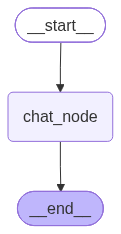

In [15]:
checkpoint=MemorySaver()
graph=StateGraph(ChatState)
#add nodes
graph.add_node('chat_node',chat_node)
#add edges
graph.add_edge(START,'chat_node')
graph.add_edge('chat_node',END)

chatbot=graph.compile(checkpointer=checkpoint)
chatbot

In [21]:
config = {"configurable": {"thread_id": "1"}}

initial_state = {
    'messages': [HumanMessage(content="what is my name?")]
}
response = chatbot.invoke(initial_state, config=config)
response['messages'][-1].content

'Your name is Berry.'

In [22]:
chatbot.get_state(config=config)

StateSnapshot(values={'messages': [HumanMessage(content='hi,my name is BERRY', additional_kwargs={}, response_metadata={}, id='16033b48-f171-4283-8c1f-3d34f1f84652'), AIMessage(content='Hello, Berry! Nice to meet you. How can I help you today?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 30, 'prompt_tokens': 77, 'total_tokens': 107, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': None, 'reasoning_tokens': 5, 'rejected_prediction_tokens': None, 'text_tokens': None}, 'prompt_tokens_details': None, 'queue_time': 0.20892661, 'prompt_time': 0.002970437, 'completion_time': 0.062529668, 'total_time': 0.065500105}, 'model_provider': 'openai', 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_9241e9962b', 'id': 'chatcmpl-7ea48128-31cf-4292-8235-573142ac381d', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a18b6d-38b2-72c6-a8e9-277f7acc17a3-0', tool_calls=[], i

In [23]:
thread_id="1"
while True:
    user_message = input("Type your message: ")
    print("User:", user_message)
    if user_message.strip().lower() in ["exit", "quit",'bye']:
        print("Exiting the chatbot.")
        break
    config={'configurable': {'thread_id': thread_id}}
    response = chatbot.invoke({'messages': [HumanMessage(content=user_message)]}, config=config)
    print('AI:', response['messages'][-1].content)

User: what are reasoning tokens in LLMs
AI: ## Reasoning Tokens in Large Language Models (LLMs)

### 1. What the term means
* **Reasoning tokens** are the individual **output tokens** that an LLM generates **while it is “thinking through” a problem** rather than directly producing the final answer.  
* They are part of the **intermediate chain‑of‑thought (CoT)** that the model writes to itself (or that a prompt forces it to write) before arriving at the final result.

In practice, a model that is asked to solve a math problem might emit something like:

```
1. Identify the variables → 2. Write the equation → 3. Solve for x → 4. Check the solution → 5. Answer: x = 7
```

Tokens 1‑4 are **reasoning tokens**; token 5 (or the final “x = 7”) is the **answer token**.

### 2. Why they matter
| Reason | Effect on the model |
|--------|----------------------|
| **Explicit reasoning** | Gives the model a scaffold to break a complex task into smaller, tractable steps, which often improves accurac